# 1 Hafta, 1 Veri Hikâyesi | #02

## Türkiye'de Asgari Ücretin Alım Gücü Analizi

### Araştırmanın Amacı

Türkiye'de asgari ücretin nominal artışını ve
enflasyondan arındırılmış reel değişimini incelemek.

### Araştırma Soruları

- Asgari ücret nominal olarak ne kadar arttı?
- Asgari ücretin satın alma gücü nasıl değişti?
- Reel asgari ücret hangi dönemde zirveye ulaştı?
- Ücret artışları enflasyon karşısında korunabildi mi?

### Analiz Dönemi

Ocak 2020 - Ekim 2026

### Veri Kaynakları

- Çalışma ve Sosyal Güvenlik Bakanlığı
- Türkiye İstatistik Kurumu (TÜİK)

## 1. Gerekli Kütüphanelerin Yüklenmesi

Bu çalışmada aşağıdaki Python kütüphaneleri kullanılacaktır:

- Pandas: Veri okuma, temizleme ve birleştirme
- NumPy: Sayısal hesaplamalar
- Matplotlib: Veri görselleştirme
- Pathlib: Dosya ve klasör yollarının yönetilmesi
- Openpyxl: Excel dosyalarının okunması

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

## 2. Dosya Yollarının Tanımlanması

Analizde kullanılacak ham Excel dosyaları data
klasöründe bulunmaktadır.

Analiz sonucunda oluşturulacak grafikler visuals
klasörüne kaydedilecektir.

Göreceli dosya yolları kullanılarak projenin farklı
bilgisayarlarda da çalıştırılabilmesi amaçlanmıştır.

In [5]:
pd.set_option("display.max_columns", None)

DATA = Path("data")
VISUALS = Path("visuals")

DATA.mkdir(exist_ok=True)
VISUALS.mkdir(exist_ok=True)

print("Çalışma klasörü:", Path.cwd())
print("Veri klasörü:", DATA.resolve())
print("Görsel klasörü:", VISUALS.resolve())

Çalışma klasörü: C:\Users\PC\Downloads\02-Asgari-Ucret-Alim-Gucu
Veri klasörü: C:\Users\PC\Downloads\02-Asgari-Ucret-Alim-Gucu\data
Görsel klasörü: C:\Users\PC\Downloads\02-Asgari-Ucret-Alim-Gucu\visuals


## 3. Veri Setlerinin Yüklenmesi

Bu çalışmada iki farklı veri seti kullanılmaktadır.

### Asgari Ücret Veri Seti

Asgari ücretin yürürlük başlangıç ve bitiş tarihleri,
net ücret, brüt ücret ve işverene maliyet bilgilerini
içermektedir.

Analizde net asgari ücret kullanılacaktır.

### TÜFE Veri Seti

Aylık tüketici fiyat endeksi ve dönemsel enflasyon
değişimlerini içermektedir.

Reel ücret hesaplamalarında aylık endeks değerleri
kullanılacaktır.

In [7]:
tufe = pd.read_excel(DATA / "tufe.xlsx")

ucret = pd.read_excel(DATA / "asgari_ucret.xlsx")

In [8]:
print("TÜFE veri seti:")
display(tufe.head())

print("Asgari ücret veri seti:")
display(ucret.head())

TÜFE veri seti:


,Endeks-Değişim,Endeks,Bir önceki aya göre değişim oranı (%),Bir önceki yılın Aralık ayına göre değişim (%),Bir önceki yılın aynı ayına göre (yıllık) değişim oranı (%),Oniki aylık ortalamalara göre değişim (%)
0,Zaman,,,,,
1,2026-10,140.77,2.58,27.52,29.77,31.23
2,2026-09,137.23,1.84,24.32,29.73,31.49
3,2026-08,134.75,1.84,22.07,31.51,31.79
4,2026-07,132.31,1.78,19.86,31.75,31.9


Asgari ücret veri seti:


,Resmî Gazete tarih ve sayı,Başlangıç,Bitiş,16+ Net ücret,16+ Brüt ücret,16+ İşverene maliyet,16 altı Net ücret,16 altı Brüt ücret,16 altı İşverene maliyet,Para birimi,Dipnot
0,31.07.1996 / 22713,01.08.1996,31.07.1997,11339802.0,17010000.0,27570750.0,9668880.0,14400000.0,29076900.0,Eski TL,NaN
1,31.07.1997 / 23066,01.08.1997,31.07.1998,23474588.0,35437500.0,50144438.0,19945486.0,29925000.0,48095025.0,Eski TL,NaN
2,31.07.1997 / 23066,01.08.1998,30.09.1998,33808514.0,47839500.0,63718446.0,29021188.0,40664250.0,57332473.0,Eski TL,NaN
3,NaN,01.10.1998,31.12.1998,34573946.0,47839500.0,66060236.0,29671816.0,40664250.0,59674264.0,Eski TL,NaN
4,31.12.1998 / 23570,01.01.1999,30.06.1999,58948065.0,78075000.0,100764360.0,50443355.0,66363750.0,90341348.0,Eski TL,NaN


In [9]:
print("TÜFE veri setinin boyutu:")
print(tufe.shape)

print("\nTÜFE sütun isimleri:")
print(tufe.columns.tolist())

print("\nAsgari ücret veri setinin boyutu:")
print(ucret.shape)

print("\nAsgari ücret sütun isimleri:")
print(ucret.columns.tolist())

TÜFE veri setinin boyutu:
(263, 6)

TÜFE sütun isimleri:
['Endeks-Değişim  ', 'Endeks  ', 'Bir önceki aya göre değişim oranı (%)  ', 'Bir önceki yılın Aralık ayına göre değişim (%)  ', 'Bir önceki yılın aynı ayına göre (yıllık) değişim oranı (%)  ', 'Oniki aylık ortalamalara göre değişim (%)  ']

Asgari ücret veri setinin boyutu:
(57, 11)

Asgari ücret sütun isimleri:
['Resmî Gazete tarih ve sayı', 'Başlangıç', 'Bitiş', '16+ Net ücret', '16+ Brüt ücret', '16+ İşverene maliyet', '16 altı Net ücret', '16 altı Brüt ücret', '16 altı İşverene maliyet', 'Para birimi', 'Dipnot']


## 4. Veri Temizleme ve Ön İşleme

İlk veri incelemesi sonucunda TÜFE veri setinin
263 satır ve 6 sütundan, asgari ücret veri setinin
ise 57 satır ve 11 sütundan oluştuğu görülmüştür.

Analiz öncesinde aşağıdaki işlemler uygulanacaktır:

- Sütun isimlerindeki gereksiz boşlukların temizlenmesi
- Analiz için gerekli sütunların seçilmesi
- Tarih formatlarının standartlaştırılması
- Sayısal veri tiplerinin düzenlenmesi
- Analiz döneminin filtrelenmesi
- Eksik ve tekrar eden verilerin kontrol edilmesi

In [11]:
tufe.columns = tufe.columns.str.strip()
ucret.columns = ucret.columns.str.strip()

print("TÜFE sütunları:")
print(tufe.columns.tolist())

print("\nAsgari ücret sütunları:")
print(ucret.columns.tolist())

TÜFE sütunları:
['Endeks-Değişim', 'Endeks', 'Bir önceki aya göre değişim oranı (%)', 'Bir önceki yılın Aralık ayına göre değişim (%)', 'Bir önceki yılın aynı ayına göre (yıllık) değişim oranı (%)', 'Oniki aylık ortalamalara göre değişim (%)']

Asgari ücret sütunları:
['Resmî Gazete tarih ve sayı', 'Başlangıç', 'Bitiş', '16+ Net ücret', '16+ Brüt ücret', '16+ İşverene maliyet', '16 altı Net ücret', '16 altı Brüt ücret', '16 altı İşverene maliyet', 'Para birimi', 'Dipnot']


### 4.1. TÜFE Veri Setinin Temizlenmesi

Reel asgari ücret hesaplamasında aylık enflasyon
değişim oranları yerine TÜFE endeks düzeyleri
kullanılacaktır.

Bu nedenle yalnızca tarih ve endeks sütunları
seçilmiştir.

Tarih bilgisi standart formata dönüştürülerek
geçersiz satırlar temizlenecek ve veriler
kronolojik olarak sıralanacaktır.

In [13]:
tufe = tufe[["Endeks-Değişim", "Endeks"]].copy()

tufe = tufe.rename(columns={
    "Endeks-Değişim": "Tarih",
    "Endeks": "TUFE"
})

display(tufe.head())

,Tarih,TUFE
0,Zaman,
1,2026-10,140.77
2,2026-09,137.23
3,2026-08,134.75
4,2026-07,132.31


In [14]:
# TÜFE verisini yeniden yükleme
tufe = pd.read_excel(DATA / "tufe.xlsx")

# Sütun isimlerini temizleme
tufe.columns = tufe.columns.str.strip()

# Gerekli sütunları seçme
tufe = tufe[["Endeks-Değişim", "Endeks"]].copy()

# Sütun isimlerini değiştirme
tufe = tufe.rename(columns={
    "Endeks-Değişim": "Tarih",
    "Endeks": "TUFE"
})

# Tarihlerdeki gereksiz boşlukları temizleme
tufe["Tarih"] = tufe["Tarih"].astype(str).str.strip()

# Tarih formatını dönüştürme
tufe["Tarih"] = pd.to_datetime(
    tufe["Tarih"],
    format="%Y-%m",
    errors="coerce"
)

# Geçersiz tarihleri kaldırma
tufe = tufe.dropna(subset=["Tarih"])

# TÜFE değerlerini sayısal formata dönüştürme
tufe["TUFE"] = pd.to_numeric(
    tufe["TUFE"],
    errors="coerce"
)

# Tarihe göre sıralama
tufe = tufe.sort_values("Tarih").reset_index(drop=True)

print("Veri boyutu:", tufe.shape)

display(tufe.head())
display(tufe.tail())

Veri boyutu: (262, 2)


,Tarih,TUFE
0,2005-01-01,3.596523
1,2005-02-01,3.597387
2,2005-03-01,3.606715
3,2005-04-01,3.632475
4,2005-05-01,3.665774


,Tarih,TUFE
257,2026-06-01,129.99
258,2026-07-01,132.31
259,2026-08-01,134.75
260,2026-09-01,137.23
261,2026-10-01,140.77


In [15]:
tufe = tufe[
    tufe["Tarih"].between(
        "2020-01-01",
        "2026-10-01"
    )
].reset_index(drop=True)

print("TÜFE veri boyutu:", tufe.shape)

display(tufe.head())
display(tufe.tail())

TÜFE veri boyutu: (82, 2)


,Tarih,TUFE
0,2020-01-01,14.025066
1,2020-02-01,14.074387
2,2020-03-01,14.154809
3,2020-04-01,14.275755
4,2020-05-01,14.470212


,Tarih,TUFE
77,2026-06-01,129.99
78,2026-07-01,132.31
79,2026-08-01,134.75
80,2026-09-01,137.23
81,2026-10-01,140.77


### 4.2. Asgari Ücret Veri Setinin Temizlenmesi

Asgari ücret veri setinde ücretlerin yürürlük
başlangıç ve bitiş tarihleri bulunmaktadır.

Çalışanın satın alma gücünü incelemek amacıyla
brüt ücret yerine net asgari ücret kullanılacaktır.

Analiz için başlangıç tarihi, bitiş tarihi ve
net ücret sütunları seçilerek veri tipleri
standartlaştırılacaktır.

Yıl içerisinde gerçekleşen ücret artışları da
analize dahil edilecektir.

In [17]:
ucret = ucret[
    ["Başlangıç", "Bitiş", "16+ Net ücret"]
].copy()

ucret = ucret.rename(columns={
    "Başlangıç": "Baslangic",
    "Bitiş": "Bitis",
    "16+ Net ücret": "Net_Asgari_Ucret"
})

display(ucret.head())

,Baslangic,Bitis,Net_Asgari_Ucret
0,01.08.1996,31.07.1997,11339802.0
1,01.08.1997,31.07.1998,23474588.0
2,01.08.1998,30.09.1998,33808514.0
3,01.10.1998,31.12.1998,34573946.0
4,01.01.1999,30.06.1999,58948065.0


In [18]:
ucret["Baslangic"] = pd.to_datetime(
    ucret["Baslangic"],
    dayfirst=True,
    errors="coerce"
)

ucret["Bitis"] = pd.to_datetime(
    ucret["Bitis"],
    dayfirst=True,
    errors="coerce"
)

ucret["Net_Asgari_Ucret"] = pd.to_numeric(
    ucret["Net_Asgari_Ucret"],
    errors="coerce"
)

print(ucret.dtypes)

display(ucret.tail(10))

Baslangic           datetime64[ns]
Bitis               datetime64[ns]
Net_Asgari_Ucret           float64
dtype: object


,Baslangic,Bitis,Net_Asgari_Ucret
47,2019-01-01,2019-12-31,2020.90
48,2020-01-01,2020-12-31,2324.71
49,2021-01-01,2021-12-31,2825.90
50,2022-01-01,2022-06-30,4253.40
51,2022-07-01,2022-12-31,5500.35
52,2023-01-01,2023-06-30,8506.80
53,2023-07-01,2023-12-31,11402.32
54,2024-01-01,2024-12-31,17002.12
55,2025-01-01,2025-12-31,22104.67
56,2026-01-01,2026-12-31,28075.50


In [19]:
ucret = ucret[
    (ucret["Bitis"] >= "2020-01-01") &
    (ucret["Baslangic"] <= "2026-10-01")
].copy()

ucret = ucret.sort_values(
    "Baslangic"
).reset_index(drop=True)

print("Asgari ücret veri boyutu:", ucret.shape)

display(ucret)

Asgari ücret veri boyutu: (9, 3)


,Baslangic,Bitis,Net_Asgari_Ucret
0,2020-01-01,2020-12-31,2324.71
1,2021-01-01,2021-12-31,2825.90
2,2022-01-01,2022-06-30,4253.40
3,2022-07-01,2022-12-31,5500.35
4,2023-01-01,2023-06-30,8506.80
5,2023-07-01,2023-12-31,11402.32
6,2024-01-01,2024-12-31,17002.12
7,2025-01-01,2025-12-31,22104.67
8,2026-01-01,2026-12-31,28075.50


## 5. Veri Kalitesi Kontrolleri

Veri temizleme işlemlerinin ardından analiz
öncesinde aşağıdaki kontroller gerçekleştirilecektir:

- Eksik değer kontrolü
- Tekrar eden tarih kontrolü
- Veri tipi kontrolü
- Gözlem sayısı kontrolü
- Tarih aralığı kontrolü

Bu kontroller ile analiz sonuçlarının
güvenilirliğinin artırılması amaçlanmaktadır.

In [21]:
print("TÜFE EKSİK DEĞERLER")
print(tufe.isna().sum())

print("\nASGARİ ÜCRET EKSİK DEĞERLER")
print(ucret.isna().sum())

print("\nTEKRAR EDEN TARİHLER")
print("TÜFE:", tufe["Tarih"].duplicated().sum())
print("Asgari ücret:", ucret["Baslangic"].duplicated().sum())

print("\nVERİ TİPLERİ")
print(tufe.dtypes)
print(ucret.dtypes)

print("\nVERİ BOYUTLARI")
print("TÜFE:", tufe.shape)
print("Asgari ücret:", ucret.shape)

print("\nTÜFE TARİH ARALIĞI")
print(tufe["Tarih"].min())
print(tufe["Tarih"].max())

print("\nEKSİK AYLAR")
beklenen_aylar = pd.date_range(
    "2020-01-01", "2026-10-01", freq="MS"
)
print(beklenen_aylar.difference(tufe["Tarih"]))

TÜFE EKSİK DEĞERLER
Tarih    0
TUFE     0
dtype: int64

ASGARİ ÜCRET EKSİK DEĞERLER
Baslangic           0
Bitis               0
Net_Asgari_Ucret    0
dtype: int64

TEKRAR EDEN TARİHLER
TÜFE: 0
Asgari ücret: 0

VERİ TİPLERİ
Tarih    datetime64[ns]
TUFE            float64
dtype: object
Baslangic           datetime64[ns]
Bitis               datetime64[ns]
Net_Asgari_Ucret           float64
dtype: object

VERİ BOYUTLARI
TÜFE: (82, 2)
Asgari ücret: (9, 3)

TÜFE TARİH ARALIĞI
2020-01-01 00:00:00
2026-10-01 00:00:00

EKSİK AYLAR
DatetimeIndex([], dtype='datetime64[ns]', freq='MS')


### 5.1. Veri Kalitesi Kontrol Sonuçları

Gerçekleştirilen kontroller sonucunda:

- TÜFE veri setinde 82 aylık gözlem bulunmaktadır.
- Asgari ücret veri setinde 9 farklı ücret dönemi bulunmaktadır.
- Her iki veri setinde eksik değer bulunmamaktadır.
- Tekrar eden tarih bulunmamaktadır.
- TÜFE serisinde eksik ay bulunmamaktadır.
- Tarih ve sayısal veri tipleri uygun formata dönüştürülmüştür.

Analiz dönemi Ocak 2020 - Ekim 2026 olarak belirlenmiştir.

Mevcut kontroller sonucunda veri setleri birleştirme
işlemine hazır hale getirilmiştir.

## 6. Veri Setlerinin Birleştirilmesi

TÜFE verileri aylık frekansta bulunurken asgari ücret
verileri belirli yürürlük dönemleri halinde bulunmaktadır.

Bu nedenle standart bir merge işlemi yerine Pandas
kütüphanesinin merge_asof() fonksiyonu kullanılacaktır.

Her ay için ilgili tarihte yürürlükte olan net asgari
ücret tutarı eşleştirilecektir.

Böylece yıl içerisinde gerçekleşen ücret artışları
da analize doğru şekilde yansıtılacaktır.

In [24]:
df = pd.merge_asof(
    tufe.sort_values("Tarih"),
    ucret.sort_values("Baslangic"),
    left_on="Tarih",
    right_on="Baslangic",
    direction="backward"
)

print("Birleştirilmiş veri boyutu:", df.shape)

display(df.head(12))
display(df.tail())

Birleştirilmiş veri boyutu: (82, 5)


,Tarih,TUFE,Baslangic,Bitis,Net_Asgari_Ucret
0,2020-01-01,14.025066,2020-01-01,2020-12-31,2324.71
1,2020-02-01,14.074387,2020-01-01,2020-12-31,2324.71
2,2020-03-01,14.154809,2020-01-01,2020-12-31,2324.71
3,2020-04-01,14.275755,2020-01-01,2020-12-31,2324.71
4,2020-05-01,14.470212,2020-01-01,2020-12-31,2324.71
5,2020-06-01,14.634196,2020-01-01,2020-12-31,2324.71
6,2020-07-01,14.719644,2020-01-01,2020-12-31,2324.71
7,2020-08-01,14.846873,2020-01-01,2020-12-31,2324.71
8,2020-09-01,14.991381,2020-01-01,2020-12-31,2324.71
9,2020-10-01,15.310868,2020-01-01,2020-12-31,2324.71


,Tarih,TUFE,Baslangic,Bitis,Net_Asgari_Ucret
77,2026-06-01,129.99,2026-01-01,2026-12-31,28075.5
78,2026-07-01,132.31,2026-01-01,2026-12-31,28075.5
79,2026-08-01,134.75,2026-01-01,2026-12-31,28075.5
80,2026-09-01,137.23,2026-01-01,2026-12-31,28075.5
81,2026-10-01,140.77,2026-01-01,2026-12-31,28075.5


In [25]:
print("Eksik değerler:")
print(df.isna().sum())

print("\nTekrar eden tarihler:")
print(df["Tarih"].duplicated().sum())

gecersiz = df[
    (df["Tarih"] < df["Baslangic"]) |
    (df["Tarih"] > df["Bitis"]) |
    (df["Net_Asgari_Ucret"].isna())
]

print("\nGeçersiz ücret eşleşmesi:")
print(len(gecersiz))

print("\n2022 ve 2023 ücret geçişleri:")

display(
    df[df["Tarih"].dt.year.isin([2022, 2023])]
    [["Tarih", "TUFE", "Net_Asgari_Ucret"]]
)

Eksik değerler:
Tarih               0
TUFE                0
Baslangic           0
Bitis               0
Net_Asgari_Ucret    0
dtype: int64

Tekrar eden tarihler:
0

Geçersiz ücret eşleşmesi:
0

2022 ve 2023 ücret geçişleri:


,Tarih,TUFE,Net_Asgari_Ucret
24,2022-01-01,23.976596,4253.40
25,2022-02-01,25.129513,4253.40
26,2022-03-01,26.502647,4253.40
27,2022-04-01,28.423653,4253.40
28,2022-05-01,29.270905,4253.40
29,2022-06-01,30.720377,4253.40
30,2022-07-01,31.446998,5500.35
31,2022-08-01,31.906280,5500.35
32,2022-09-01,32.887673,5500.35
33,2022-10-01,34.053470,5500.35


In [26]:
df = df[
    ["Tarih", "TUFE", "Net_Asgari_Ucret"]
].copy()

display(df.head())
display(df.tail())

print("Analitik veri seti boyutu:", df.shape)

,Tarih,TUFE,Net_Asgari_Ucret
0,2020-01-01,14.025066,2324.71
1,2020-02-01,14.074387,2324.71
2,2020-03-01,14.154809,2324.71
3,2020-04-01,14.275755,2324.71
4,2020-05-01,14.470212,2324.71


,Tarih,TUFE,Net_Asgari_Ucret
77,2026-06-01,129.99,28075.5
78,2026-07-01,132.31,28075.5
79,2026-08-01,134.75,28075.5
80,2026-09-01,137.23,28075.5
81,2026-10-01,140.77,28075.5


Analitik veri seti boyutu: (82, 3)


## 7. Nominal ve Reel Asgari Ücret Hesaplamaları

Nominal asgari ücret, ilgili dönemde çalışanların
TL cinsinden elde ettiği net asgari ücret tutarıdır.

Reel asgari ücret ise nominal ücretin enflasyon
etkisinden arındırılmış değerini ifade etmektedir.

Karşılaştırma amacıyla Ocak 2020 baz dönem olarak
belirlenmiştir.

Bu bölümde aşağıdaki göstergeler hesaplanacaktır:

- Normalize edilmiş TÜFE endeksi
- Nominal asgari ücret endeksi
- Reel asgari ücret (Ocak 2020 fiyatlarıyla)
- Reel asgari ücret endeksi
- Yıllık nominal ücret değişimi
- Yıllık reel ücret değişimi
- Baz dönem satın alma gücünü korumak için gereken ücret

In [28]:
baz_tufe = df["TUFE"].iloc[0]

baz_ucret = df["Net_Asgari_Ucret"].iloc[0]

df["TUFE_Normalize"] = (
    df["TUFE"] / baz_tufe * 100
)

df["Nominal_Endeks"] = (
    df["Net_Asgari_Ucret"] / baz_ucret * 100
)

print("Baz dönem TÜFE:", baz_tufe)
print("Baz dönem net asgari ücret:", baz_ucret)

display(df.head())

Baz dönem TÜFE: 14.025066
Baz dönem net asgari ücret: 2324.71


,Tarih,TUFE,Net_Asgari_Ucret,TUFE_Normalize,Nominal_Endeks
0,2020-01-01,14.025066,2324.71,100.000000,100.0
1,2020-02-01,14.074387,2324.71,100.351663,100.0
2,2020-03-01,14.154809,2324.71,100.925079,100.0
3,2020-04-01,14.275755,2324.71,101.787435,100.0
4,2020-05-01,14.470212,2324.71,103.173932,100.0


In [29]:
df["Reel_Ucret"] = (
    df["Net_Asgari_Ucret"] /
    (df["TUFE_Normalize"] / 100)
)

df["Reel_Endeks"] = (
    df["Reel_Ucret"] / baz_ucret * 100
)

display(df.head())
display(df.tail())

,Tarih,TUFE,Net_Asgari_Ucret,TUFE_Normalize,Nominal_Endeks,Reel_Ucret,Reel_Endeks
0,2020-01-01,14.025066,2324.71,100.000000,100.0,2324.710000,100.000000
1,2020-02-01,14.074387,2324.71,100.351663,100.0,2316.563498,99.649569
2,2020-03-01,14.154809,2324.71,100.925079,100.0,2303.401705,99.083400
3,2020-04-01,14.275755,2324.71,101.787435,100.0,2283.886994,98.243953
4,2020-05-01,14.470212,2324.71,103.173932,100.0,2253.195128,96.923708


,Tarih,TUFE,Net_Asgari_Ucret,TUFE_Normalize,Nominal_Endeks,Reel_Ucret,Reel_Endeks
77,2026-06-01,129.99,28075.5,926.840558,1207.699025,3029.161785,130.302781
78,2026-07-01,132.31,28075.5,943.382370,1207.699025,2976.046712,128.017977
79,2026-08-01,134.75,28075.5,960.779792,1207.699025,2922.157629,125.699878
80,2026-09-01,137.23,28075.5,978.462419,1207.699025,2869.348834,123.428248
81,2026-10-01,140.77,28075.5,1003.702942,1207.699025,2797.192161,120.324348


In [30]:
df["Yillik_Nominal_Degisim"] = (
    df["Net_Asgari_Ucret"].pct_change(12) * 100
)

df["Yillik_Reel_Degisim"] = (
    df["Reel_Ucret"].pct_change(12) * 100
)

display(df.tail(12))

,Tarih,TUFE,Net_Asgari_Ucret,TUFE_Normalize,Nominal_Endeks,Reel_Ucret,Reel_Endeks,Yillik_Nominal_Degisim,Yillik_Reel_Degisim
70,2025-11-01,109.415936,22104.67,780.145605,950.857096,2833.403131,121.882004,30.011257,-0.811432
71,2025-12-01,110.386963,22104.67,787.069116,950.857096,2808.478893,120.809860,30.011257,-0.673127
72,2026-01-01,115.730000,28075.50,825.165457,1207.699025,3402.408541,146.358408,27.011622,-2.786897
73,2026-02-01,119.160000,28075.50,849.621670,1207.699025,3304.470800,142.145506,27.011622,-3.438796
74,2026-03-01,121.470000,28075.50,866.092181,1207.699025,3241.629542,139.442319,27.011622,-2.944881
75,2026-04-01,126.550000,28075.50,902.313044,1207.699025,3111.503283,133.844793,27.011622,-4.049291
76,2026-05-01,128.720000,28075.50,917.785342,1207.699025,3059.048636,131.588398,27.011622,-4.225154
77,2026-06-01,129.990000,28075.50,926.840558,1207.699025,3029.161785,130.302781,27.011622,-3.858489
78,2026-07-01,132.310000,28075.50,943.382370,1207.699025,2976.046712,128.017977,27.011622,-3.599489
79,2026-08-01,134.750000,28075.50,960.779792,1207.699025,2922.157629,125.699878,27.011622,-3.418608


In [31]:
df["Gerekli_Ucret"] = (
    baz_ucret * df["TUFE_Normalize"] / 100
)

df["Ucret_Farki"] = (
    df["Net_Asgari_Ucret"] -
    df["Gerekli_Ucret"]
)

display(
    df[[
        "Tarih",
        "Net_Asgari_Ucret",
        "Reel_Ucret",
        "Gerekli_Ucret",
        "Ucret_Farki"
    ]].tail(12)
)

,Tarih,Net_Asgari_Ucret,Reel_Ucret,Gerekli_Ucret,Ucret_Farki
70,2025-11-01,22104.67,2833.403131,18136.122894,3968.547106
71,2025-12-01,22104.67,2808.478893,18297.074449,3807.595551
72,2026-01-01,28075.50,3402.408541,19182.703903,8892.796097
73,2026-02-01,28075.50,3304.470800,19751.239930,8324.260070
74,2026-03-01,28075.50,3241.629542,20134.131540,7941.368460
75,2026-04-01,28075.50,3111.503283,20976.161574,7099.338426
76,2026-05-01,28075.50,3059.048636,21335.847632,6739.652368
77,2026-06-01,28075.50,3029.161785,21546.355140,6529.144860
78,2026-07-01,28075.50,2976.046712,21930.904290,6144.595710
79,2026-08-01,28075.50,2922.157629,22335.343912,5740.156088


## 8. Temel Bulgular ve İleri Analiz

Bu bölümde asgari ücretin nominal ve reel
değişimleri detaylı olarak incelenecektir.

Analiz kapsamında:

- Toplam nominal ücret değişimi
- Kümülatif enflasyon
- Toplam reel ücret değişimi
- Reel ücretin zirve ve dip noktaları
- Zirveden itibaren satın alma gücü değişimi
- Ücret artışlarının dönemsel etkileri
- Zam sonrasında satın alma gücü kayıpları
- Yıllık ortalama reel ücret değişimleri

hesaplanacaktır.

Bu göstergeler ile asgari ücretin yalnızca
nominal değişimi değil, zaman içerisindeki
satın alma gücü dinamikleri de incelenecektir.

In [33]:
ilk = df.iloc[0]
son = df.iloc[-1]

nominal_degisim = (
    son["Nominal_Endeks"] - 100
)

kumulatif_enflasyon = (
    son["TUFE_Normalize"] - 100
)

reel_degisim = (
    son["Reel_Endeks"] - 100
)

print(f"Analiz başlangıcı: {ilk['Tarih']:%Y-%m}")
print(f"Analiz bitişi: {son['Tarih']:%Y-%m}")

print(f"\nNominal ücret artışı: %{nominal_degisim:.2f}")
print(f"Kümülatif enflasyon: %{kumulatif_enflasyon:.2f}")
print(f"Reel ücret değişimi: %{reel_degisim:.2f}")

print(f"\nSon 12 aylık nominal değişim: %{son['Yillik_Nominal_Degisim']:.2f}")
print(f"Son 12 aylık reel değişim: %{son['Yillik_Reel_Degisim']:.2f}")

print(f"\nGerekli ücret: {son['Gerekli_Ucret']:.2f} TL")
print(f"Ücret farkı: {son['Ucret_Farki']:.2f} TL")

Analiz başlangıcı: 2020-01
Analiz bitişi: 2026-10

Nominal ücret artışı: %1107.70
Kümülatif enflasyon: %903.70
Reel ücret değişimi: %20.32

Son 12 aylık nominal değişim: %27.01
Son 12 aylık reel değişim: %-2.12

Gerekli ücret: 23333.18 TL
Ücret farkı: 4742.32 TL


### 8.1. Reel Asgari Ücretin Zirve ve Dip Noktaları

Reel asgari ücret endeksinin analiz dönemi
içerisindeki en yüksek ve en düşük değerleri
belirlenecektir.

Ayrıca en yüksek satın alma gücüne ulaşılan
dönem ile son gözlem karşılaştırılarak
zirveden itibaren gerçekleşen değişim
hesaplanacaktır.

In [35]:
zirve = df.loc[df["Reel_Endeks"].idxmax()]

dip = df.loc[df["Reel_Endeks"].idxmin()]

zirveden_degisim = (
    son["Reel_Endeks"] /
    zirve["Reel_Endeks"] - 1
) * 100

print("REEL ASGARİ ÜCRET ZİRVESİ")
print(f"Tarih: {zirve['Tarih']:%Y-%m}")
print(f"Reel endeks: {zirve['Reel_Endeks']:.2f}")
print(f"Reel ücret: {zirve['Reel_Ucret']:.2f} TL")

print("\nREEL ASGARİ ÜCRET DİP NOKTASI")
print(f"Tarih: {dip['Tarih']:%Y-%m}")
print(f"Reel endeks: {dip['Reel_Endeks']:.2f}")
print(f"Reel ücret: {dip['Reel_Ucret']:.2f} TL")

print(f"\nZirveden itibaren değişim: %{zirveden_degisim:.2f}")

REEL ASGARİ ÜCRET ZİRVESİ
Tarih: 2024-01
Reel endeks: 164.57
Reel ücret: 3825.87 TL

REEL ASGARİ ÜCRET DİP NOKTASI
Tarih: 2021-12
Reel endeks: 79.00
Reel ücret: 1836.56 TL

Zirveden itibaren değişim: %-26.89


### 8.2. Ücret Artışlarının Enflasyon Karşısındaki Etkisi

Asgari ücretin değiştiği dönemler tespit edilerek
her ücret döneminin başlangıcındaki ve sonundaki
reel ücret değerleri karşılaştırılacaktır.

Bu analiz ile ücret artışlarının sağladığı satın
alma gücünün bir sonraki ücret düzenlemesine
kadar ne ölçüde korunduğu incelenecektir.

Henüz tamamlanmamış ücret dönemleri için
mevcut son gözlem kullanılacaktır.

In [37]:
df["Ucret_Donemi"] = (
    df["Net_Asgari_Ucret"]
    .ne(df["Net_Asgari_Ucret"].shift())
    .cumsum()
)

display(
    df[[
        "Tarih",
        "Net_Asgari_Ucret",
        "Ucret_Donemi"
    ]].head(40)
)

print("Ücret dönem sayısı:", df["Ucret_Donemi"].nunique())

,Tarih,Net_Asgari_Ucret,Ucret_Donemi
0,2020-01-01,2324.71,1
1,2020-02-01,2324.71,1
2,2020-03-01,2324.71,1
3,2020-04-01,2324.71,1
4,2020-05-01,2324.71,1
5,2020-06-01,2324.71,1
6,2020-07-01,2324.71,1
7,2020-08-01,2324.71,1
8,2020-09-01,2324.71,1
9,2020-10-01,2324.71,1


Ücret dönem sayısı: 9


In [38]:
donem_analizi = df.groupby("Ucret_Donemi").agg(

    Baslangic=("Tarih", "first"),

    Bitis=("Tarih", "last"),

    Net_Ucret=("Net_Asgari_Ucret", "first"),

    Ay_Sayisi=("Tarih", "count"),

    Baslangic_Reel=("Reel_Endeks", "first"),

    Bitis_Reel=("Reel_Endeks", "last")

).reset_index()

donem_analizi["Reel_Degisim"] = (
    donem_analizi["Bitis_Reel"] /
    donem_analizi["Baslangic_Reel"] - 1
) * 100

display(donem_analizi.round(2))

,Ucret_Donemi,Baslangic,Bitis,Net_Ucret,Ay_Sayisi,Baslangic_Reel,Bitis_Reel,Reel_Degisim
0,1,2020-01-01,2020-12-01,2324.71,12,100.00,88.44,-11.56
1,2,2021-01-01,2021-12-01,2825.90,12,105.73,79.00,-25.28
2,3,2022-01-01,2022-06-01,4253.40,6,107.02,83.53,-21.95
3,4,2022-07-01,2022-12-01,5500.35,6,105.52,93.61,-11.29
4,5,2023-01-01,2023-06-01,8506.80,6,135.75,120.87,-10.96
5,6,2023-07-01,2023-12-01,11402.32,6,147.97,117.77,-20.41
6,7,2024-01-01,2024-12-01,17002.12,12,164.57,121.63,-26.09
7,8,2025-01-01,2025-12-01,22104.67,12,150.55,120.81,-19.76
8,9,2026-01-01,2026-10-01,28075.50,10,146.36,120.32,-17.79


In [39]:
en_yuksek_kayip = donem_analizi.loc[
    donem_analizi["Reel_Degisim"].idxmin()
]

print("EN YÜKSEK DÖNEMSEL ALIM GÜCÜ KAYBI")

print(f"Başlangıç: {en_yuksek_kayip['Baslangic']:%Y-%m}")

print(f"Bitiş: {en_yuksek_kayip['Bitis']:%Y-%m}")

print(f"Reel değişim: %{en_yuksek_kayip['Reel_Degisim']:.2f}")

EN YÜKSEK DÖNEMSEL ALIM GÜCÜ KAYBI
Başlangıç: 2024-01
Bitiş: 2024-12
Reel değişim: %-26.09


### 8.3. Yıllık Ortalama Reel Asgari Ücret

Yıl içerisinde gerçekleşen ücret artışları ve
enflasyon değişimleri nedeniyle yalnızca yıl
sonu değerlerinin karşılaştırılması yeterli
olmayabilir.

Bu nedenle her yıl için aylık reel ücret
değerlerinin aritmetik ortalaması hesaplanacaktır.

2026 yılı yalnızca Ocak-Ekim dönemini kapsadığı
için tam yıllardan ayrı değerlendirilmelidir.

In [41]:
df["Yil"] = df["Tarih"].dt.year

yillik_analiz = df.groupby("Yil").agg(

    Ay_Sayisi=("Tarih", "count"),

    Ortalama_Nominal_Ucret=("Net_Asgari_Ucret", "mean"),

    Ortalama_Reel_Ucret=("Reel_Ucret", "mean"),

    Ortalama_Reel_Endeks=("Reel_Endeks", "mean")

).reset_index()

display(yillik_analiz.round(2))

,Yil,Ay_Sayisi,Ortalama_Nominal_Ucret,Ortalama_Reel_Ucret,Ortalama_Reel_Endeks
0,2020,12,2324.71,2213.56,95.22
1,2021,12,2825.90,2260.13,97.22
2,2022,12,4876.88,2254.27,96.97
3,2023,12,9954.56,2993.95,128.79
4,2024,12,17002.12,3245.48,139.61
5,2025,12,22104.67,3116.08,134.04
6,2026,10,28075.50,3071.30,132.12


## 9. Veri Görselleştirme

Analiz sonucunda elde edilen bulguların daha
anlaşılır hale getirilmesi amacıyla Matplotlib
kütüphanesi kullanılarak grafikler oluşturulacaktır.

Bu bölümde:

- Nominal asgari ücret ve TÜFE karşılaştırması
- Reel asgari ücretin tarihsel değişimi
- Ücret dönemlerindeki satın alma gücü kayıpları
- Yıllık ortalama reel asgari ücret
- 2026 yılı satın alma gücü değişimi

görselleştirilecektir.

Oluşturulan grafikler visuals klasörüne yüksek
çözünürlüklü PNG formatında kaydedilecektir.

In [43]:
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 120,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.15
})

LACIVERT = "#172554"
MAVI = "#2563EB"
TURUNCU = "#E8791B"
YESIL = "#15803D"
KIRMIZI = "#B91C1C"
GRI = "#64748B"

KAYNAK = (
    "Kaynak: ÇSGB, TÜİK | Analiz: Python / Pandas"
)

VISUALS.mkdir(exist_ok=True)

### 9.1. Nominal Asgari Ücret ve TÜFE Karşılaştırması

Ocak 2020 baz alınarak oluşturulan nominal
asgari ücret ve TÜFE endeksleri karşılaştırılmıştır.

Bu grafik ücret artışlarının genel fiyat
düzeyindeki değişime göre seyrini göstermektedir.

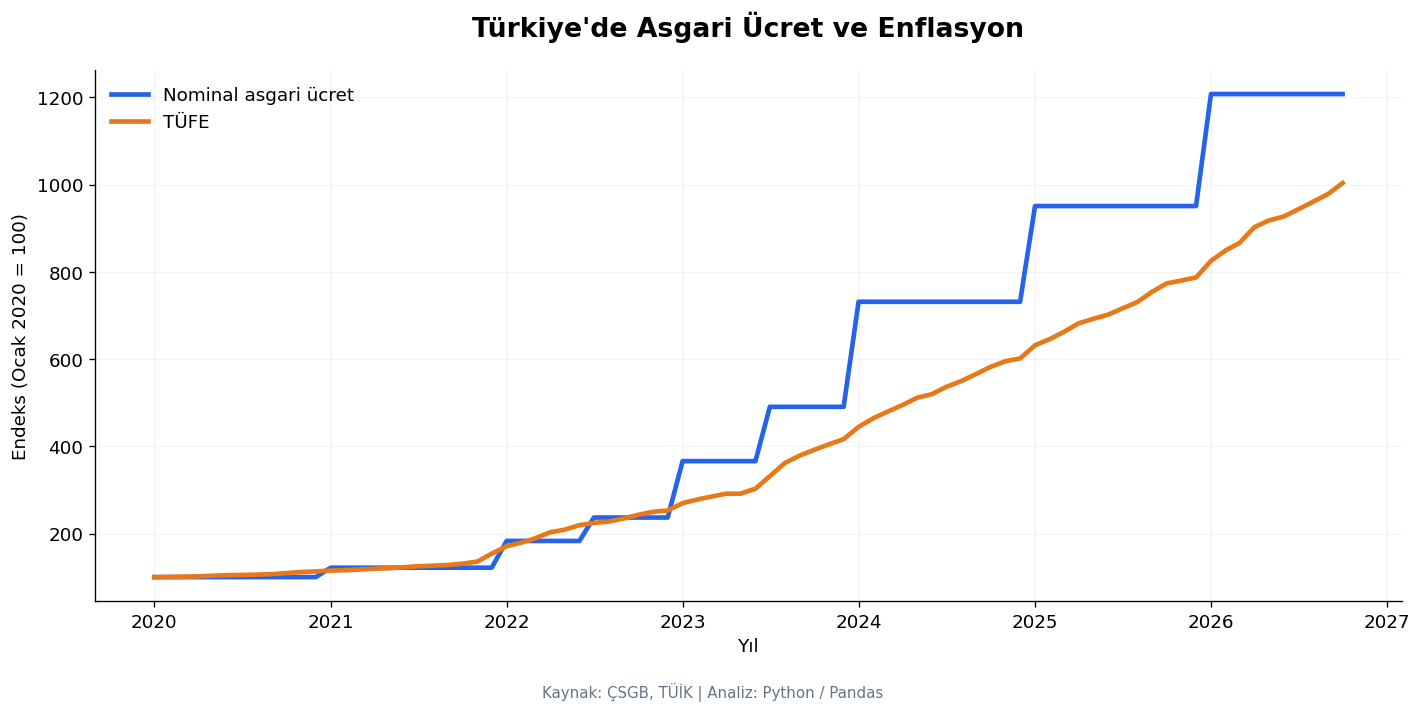

In [45]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    df["Tarih"],
    df["Nominal_Endeks"],
    color=MAVI,
    linewidth=2.8,
    label="Nominal asgari ücret"
)

ax.plot(
    df["Tarih"],
    df["TUFE_Normalize"],
    color=TURUNCU,
    linewidth=2.8,
    label="TÜFE"
)

ax.set_title(
    "Türkiye'de Asgari Ücret ve Enflasyon",
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Endeks (Ocak 2020 = 100)")
ax.set_xlabel("Yıl")

ax.legend(frameon=False)

fig.text(
    0.5, 0.02, KAYNAK,
    ha="center", color=GRI, fontsize=9
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(
    VISUALS / "nominal_ucret_tufe.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.2. Reel Asgari Ücretin Tarihsel Değişimi

Asgari ücretin enflasyondan arındırılmış satın
alma gücü Ocak 2020 baz alınarak incelenmiştir.

Grafik üzerinde analiz döneminin en yüksek,
en düşük ve son reel ücret değerleri
işaretlenmiştir.

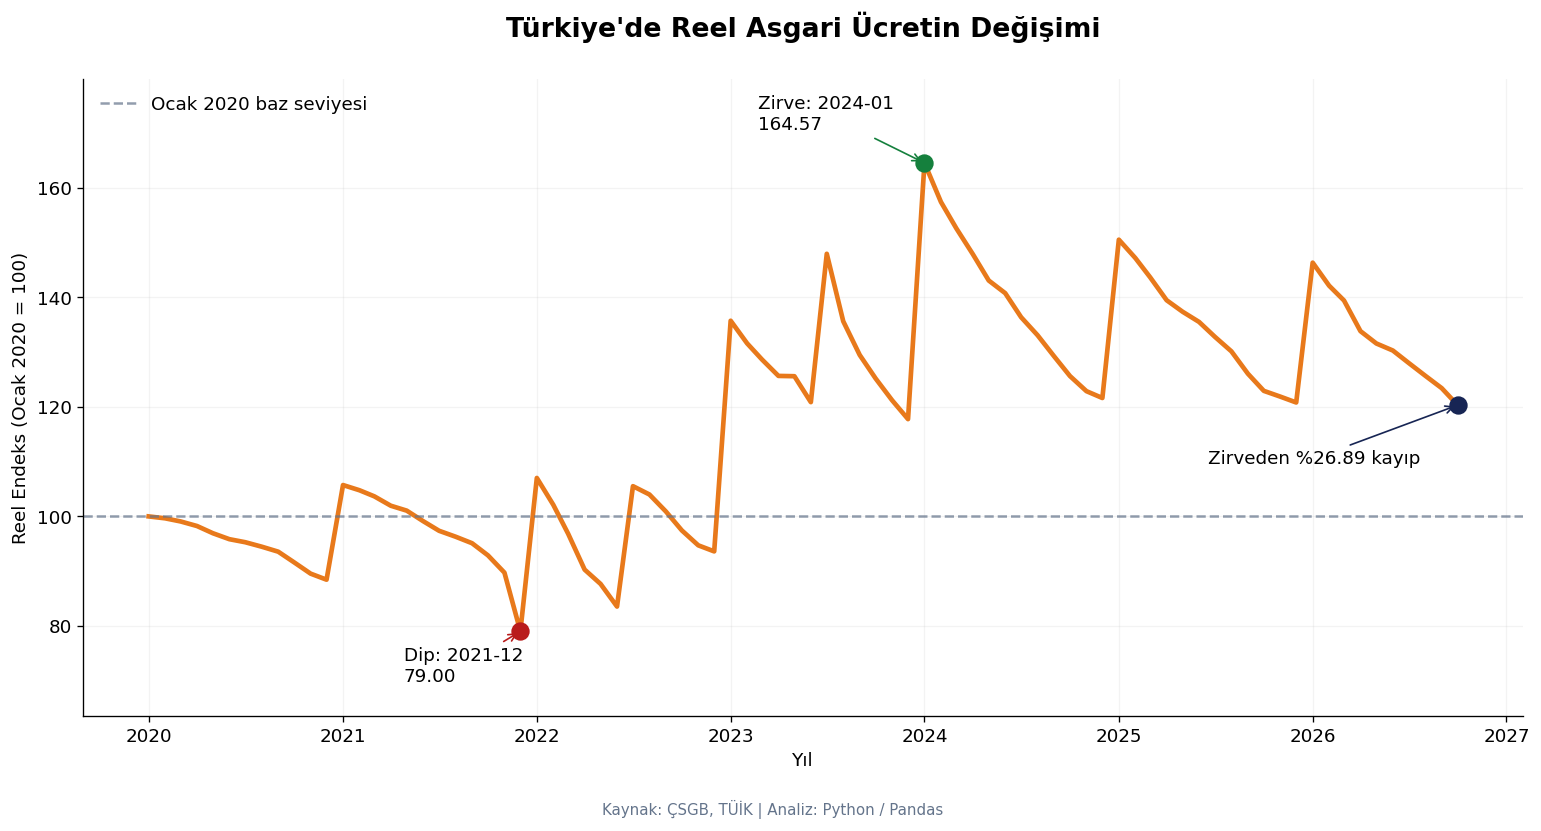

In [47]:
fig, ax = plt.subplots(figsize=(13, 7))

ax.plot(
    df["Tarih"],
    df["Reel_Endeks"],
    color=TURUNCU,
    linewidth=2.8
)

ax.axhline(
    100,
    color=GRI,
    linestyle="--",
    alpha=0.7,
    label="Ocak 2020 baz seviyesi"
)

ax.scatter(
    zirve["Tarih"],
    zirve["Reel_Endeks"],
    color=YESIL,
    s=100,
    zorder=5
)

ax.scatter(
    dip["Tarih"],
    dip["Reel_Endeks"],
    color=KIRMIZI,
    s=100,
    zorder=5
)

ax.scatter(
    son["Tarih"],
    son["Reel_Endeks"],
    color=LACIVERT,
    s=100,
    zorder=5
)

ax.annotate(
    f"Zirve: {zirve['Tarih']:%Y-%m}\n"
    f"{zirve['Reel_Endeks']:.2f}",
    xy=(zirve["Tarih"], zirve["Reel_Endeks"]),
    xytext=(-100, 20),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color=YESIL)
)

ax.annotate(
    f"Dip: {dip['Tarih']:%Y-%m}\n"
    f"{dip['Reel_Endeks']:.2f}",
    xy=(dip["Tarih"], dip["Reel_Endeks"]),
    xytext=(-70, -30),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color=KIRMIZI)
)

ax.annotate(
    f"Zirveden %{abs(zirveden_degisim):.2f} kayıp",
    xy=(son["Tarih"], son["Reel_Endeks"]),
    xytext=(-150, -35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color=LACIVERT)
)

ax.set_title(
    "Türkiye'de Reel Asgari Ücretin Değişimi",
    fontweight="bold",
    pad=25
)

ax.set_ylabel("Reel Endeks (Ocak 2020 = 100)")
ax.set_xlabel("Yıl")

ax.margins(y=0.18)

ax.legend(frameon=False, loc="upper left")

fig.text(
    0.5, 0.02, KAYNAK,
    ha="center", color=GRI, fontsize=9
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(
    VISUALS / "reel_asgari_ucret.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.3. Ücret Dönemlerinde Satın Alma Gücü Kayıpları

Her ücret döneminin ilk ve son ayındaki reel
ücret endeksi karşılaştırılarak dönem içindeki
satın alma gücü değişimi hesaplanmıştır.

Ücret dönemlerinin uzunlukları farklı olduğu
için sonuçlar eşit süreli değişim oranları
olarak değerlendirilmemelidir.

2026 yılı Ocak-Ekim dönemini kapsamaktadır.

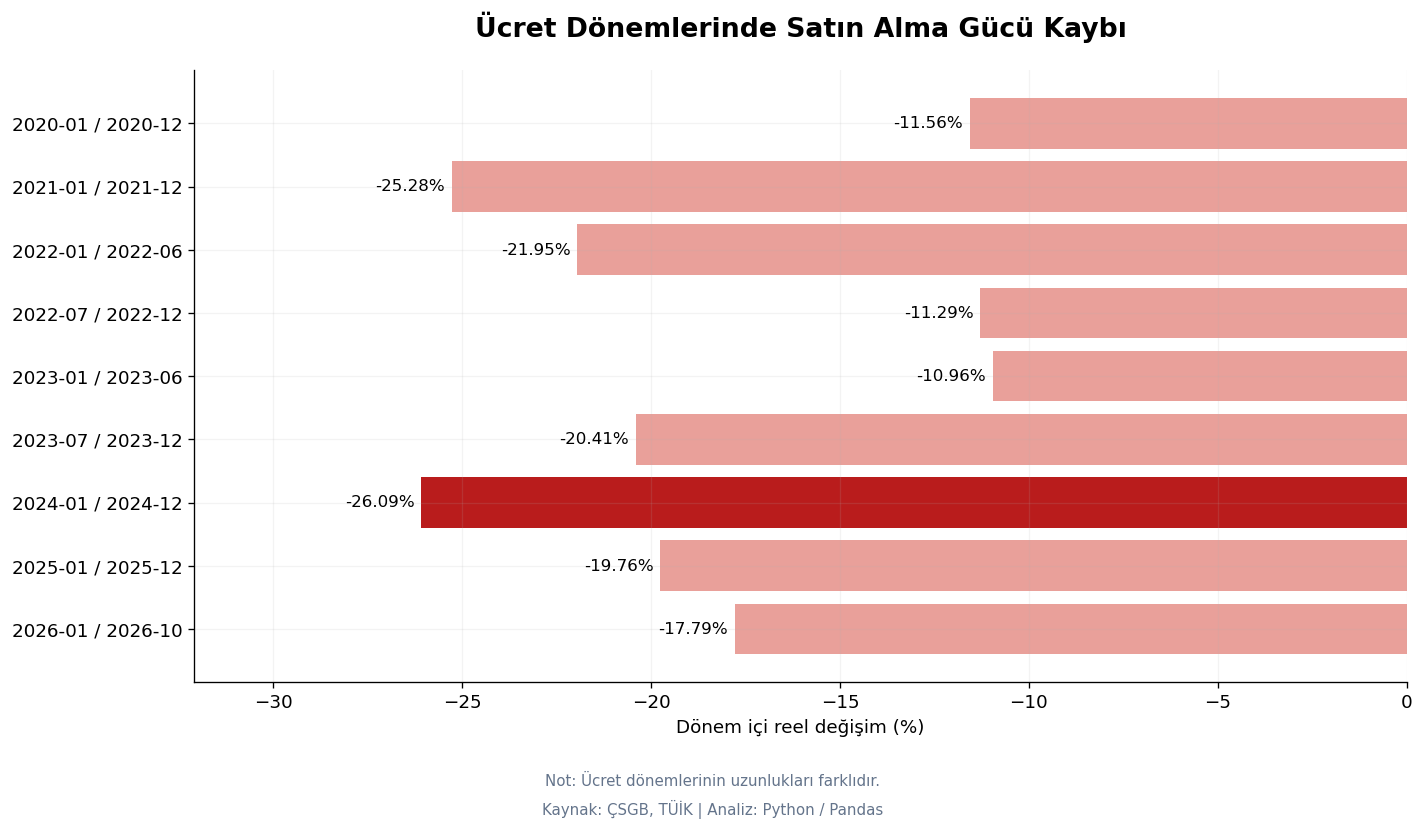

In [49]:
donem_analizi["Donem_Etiketi"] = (
    donem_analizi["Baslangic"].dt.strftime("%Y-%m")
    + " / " +
    donem_analizi["Bitis"].dt.strftime("%Y-%m")
)

fig, ax = plt.subplots(figsize=(12, 7))

renkler = [
    KIRMIZI if x == donem_analizi["Reel_Degisim"].min()
    else "#E9A09A"
    for x in donem_analizi["Reel_Degisim"]
]

bars = ax.barh(
    donem_analizi["Donem_Etiketi"],
    donem_analizi["Reel_Degisim"],
    color=renkler
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4,
    fontsize=10
)

ax.invert_yaxis()

ax.set_xlim(
    donem_analizi["Reel_Degisim"].min() - 6,
    0
)

ax.set_title(
    "Ücret Dönemlerinde Satın Alma Gücü Kaybı",
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Dönem içi reel değişim (%)")

fig.text(
    0.5, 0.055,
    "Not: Ücret dönemlerinin uzunlukları farklıdır.",
    ha="center", color=GRI, fontsize=9
)

fig.text(
    0.5, 0.02, KAYNAK,
    ha="center", color=GRI, fontsize=9
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

fig.savefig(
    VISUALS / "donemsel_alim_gucu_kaybi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.4. Yıllık Ortalama Reel Asgari Ücret

Her yılın aylık reel ücret endekslerinin
aritmetik ortalaması hesaplanarak yıllar
arasındaki satın alma gücü karşılaştırılmıştır.

2026 yılı tamamlanmadığından farklı renkle
gösterilmiştir.

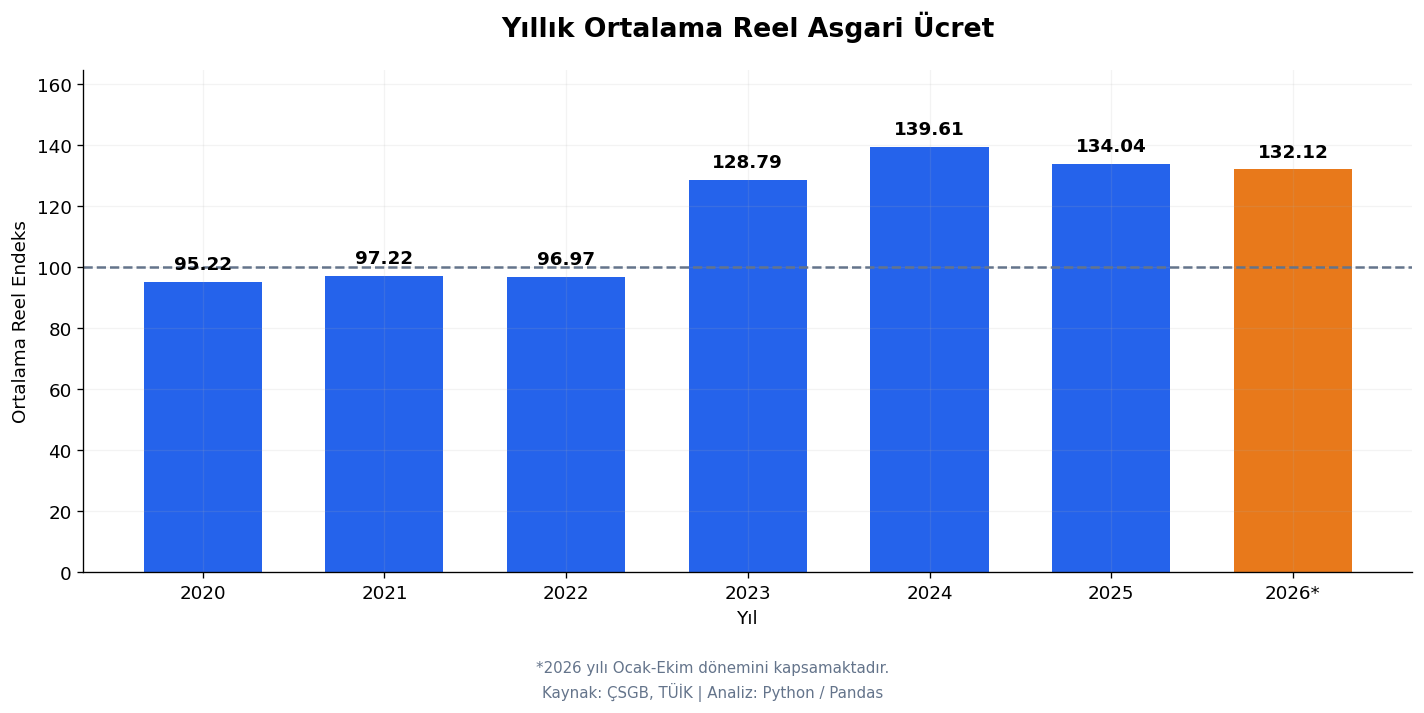

In [51]:
fig, ax = plt.subplots(figsize=(12, 6))

renkler = [
    TURUNCU if ay < 12 else MAVI
    for ay in yillik_analiz["Ay_Sayisi"]
]

etiketler = [
    f"{yil}*" if ay < 12 else str(yil)
    for yil, ay in zip(
        yillik_analiz["Yil"],
        yillik_analiz["Ay_Sayisi"]
    )
]

bars = ax.bar(
    etiketler,
    yillik_analiz["Ortalama_Reel_Endeks"],
    color=renkler,
    width=0.65
)

ax.bar_label(
    bars,
    fmt="%.2f",
    padding=5,
    fontweight="bold"
)

ax.axhline(
    100,
    color=GRI,
    linestyle="--"
)

ax.set_ylim(
    0,
    yillik_analiz["Ortalama_Reel_Endeks"].max() * 1.18
)

ax.set_title(
    "Yıllık Ortalama Reel Asgari Ücret",
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Ortalama Reel Endeks")
ax.set_xlabel("Yıl")

fig.text(
    0.5, 0.055,
    "*2026 yılı Ocak-Ekim dönemini kapsamaktadır.",
    ha="center", color=GRI, fontsize=9
)

fig.text(
    0.5, 0.02, KAYNAK,
    ha="center", color=GRI, fontsize=9
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

fig.savefig(
    VISUALS / "yillik_ortalama_reel_ucret.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.5. 2026 Yılında Asgari Ücretin Satın Alma Gücü

2026 yılı Ocak-Ekim döneminde nominal asgari
ücret sabit kalırken enflasyonun satın alma
gücü üzerindeki etkisi incelenmiştir.

Ocak 2026 değeri 100 kabul edilerek yıl
içerisindeki reel değişim görselleştirilmiştir.

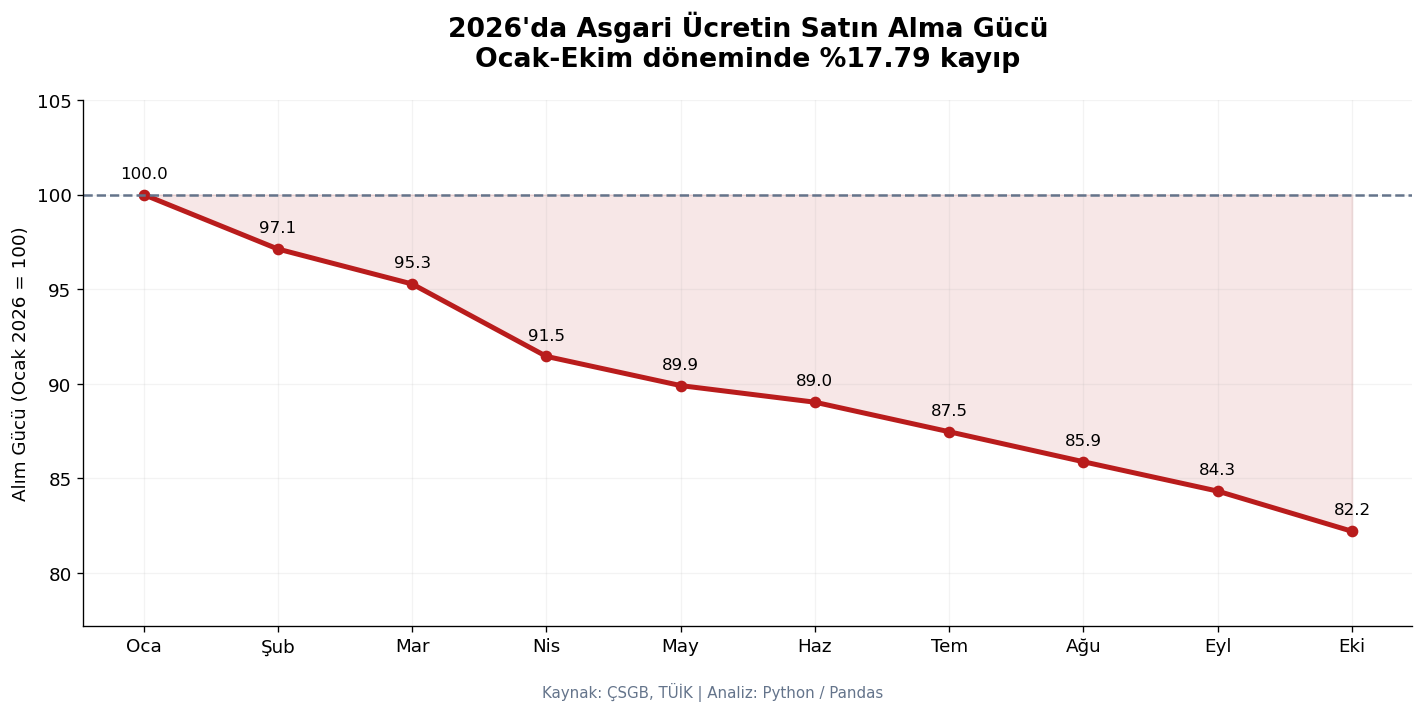

In [53]:
df_2026 = df[df["Yil"] == 2026].copy()

df_2026["Alim_Gucu_2026"] = (
    df_2026["Reel_Endeks"] /
    df_2026["Reel_Endeks"].iloc[0] * 100
)

kayip_2026 = (
    df_2026["Alim_Gucu_2026"].iloc[-1] - 100
)

aylar = [
    "Oca", "Şub", "Mar", "Nis", "May",
    "Haz", "Tem", "Ağu", "Eyl", "Eki",
    "Kas", "Ara"
]

etiketler = [
    aylar[ay - 1]
    for ay in df_2026["Tarih"].dt.month
]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    etiketler,
    df_2026["Alim_Gucu_2026"],
    color=KIRMIZI,
    linewidth=3,
    marker="o"
)

ax.fill_between(
    etiketler,
    df_2026["Alim_Gucu_2026"],
    100,
    color=KIRMIZI,
    alpha=0.10
)

ax.axhline(
    100,
    color=GRI,
    linestyle="--"
)

ax.set_title(
    "2026'da Asgari Ücretin Satın Alma Gücü\n"
    f"Ocak-Ekim döneminde %{abs(kayip_2026):.2f} kayıp",
    fontweight="bold",
    pad=20
)

ax.set_ylabel("Alım Gücü (Ocak 2026 = 100)")

ax.set_ylim(
    df_2026["Alim_Gucu_2026"].min() - 5,
    105
)

for i, deger in enumerate(df_2026["Alim_Gucu_2026"]):
    ax.annotate(
        f"{deger:.1f}",
        (i, deger),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10
    )

fig.text(
    0.5, 0.02, KAYNAK,
    ha="center", color=GRI, fontsize=9
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(
    VISUALS / "2026_alim_gucu.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
print("Kaydedilen görseller:\n")

for dosya in sorted(VISUALS.glob("*.png")):
    print(dosya.name)

Kaydedilen görseller:

2026_alim_gucu.png
donemsel_alim_gucu_kaybi.png
nominal_ucret_tufe.png
reel_asgari_ucret.png
yillik_ortalama_reel_ucret.png


## 10. Bulgular ve Sonuç

### 10.1. Temel Bulgular

Ocak 2020 – Ekim 2026 dönemini kapsayan 82 aylık veri seti üzerinde gerçekleştirilen analiz sonucunda aşağıdaki bulgular elde edilmiştir:

- Net asgari ücret 2.324,71 TL'den 28.075,50 TL'ye yükselerek nominal olarak %1.107,70 artmıştır.
- Aynı dönemde kümülatif enflasyon %903,70 olarak hesaplanmıştır.
- Enflasyondan arındırılmış reel asgari ücret %20,32 artmıştır.
- Reel asgari ücret endeksi Ocak 2024'te 164,57 ile analiz döneminin en yüksek seviyesine ulaşmıştır.
- Aralık 2021'de 79,00 ile analiz döneminin en düşük seviyesi görülmüştür.
- Ekim 2026 itibarıyla reel asgari ücret, Ocak 2024 zirvesinden %26,89 gerilemiştir.
- Son 12 aylık dönemde nominal asgari ücret %27,01 artarken reel asgari ücret %2,12 azalmıştır.

### 10.2. Ücret Dönemlerinin Değerlendirilmesi

İncelenen dokuz ücret döneminin tamamında ilk ve son aylar arasında satın alma gücü kaybı gözlemlenmiştir.

En yüksek toplam dönem içi kayıp %26,09 ile Ocak–Aralık 2024 döneminde gerçekleşmiştir.

2026 yılının Ocak–Ekim döneminde ise satın alma gücü %17,79 azalmıştır.

Bu bulgular, nominal ücret artışlarının satın alma gücü üzerindeki etkisinin enflasyon nedeniyle zaman içerisinde azalabildiğini göstermektedir.

### 10.3. Yıllık Ortalama Reel Ücret

Tam takvim yılları arasında en yüksek ortalama reel ücret endeksi 139,61 ile 2024 yılında gerçekleşmiştir.

2025 yılında bu değer 134,04'e gerilemiştir. 2026 yılının ilk on ayında ise ortalama reel ücret endeksi 132,12 olarak hesaplanmıştır.

### 10.4. Sonuç

Asgari ücretin nominal olarak artması, satın alma gücünün aynı oranda arttığı anlamına gelmemektedir.

Analiz döneminin tamamında reel ücret artışı gerçekleşmiş olmakla birlikte, ücret güncellemeleri arasındaki dönemlerde satın alma gücünün gerilediği gözlemlenmiştir.

Bu nedenle ücret politikalarının değerlendirilmesinde nominal artışların yanı sıra reel ücret değişimleri ve satın alma gücünün zaman içerisindeki sürdürülebilirliği de dikkate alınmalıdır.

## 11. Analizin Sınırlılıkları

- Analizde TÜİK tarafından yayımlanan genel TÜFE endeksi kullanılmıştır. Asgari ücretli hanelerin tüketim sepeti genel TÜFE sepetinden farklı olabilir.
- Bölgesel fiyat farklılıkları dikkate alınmamıştır.
- Kira, gıda, ulaşım ve enerji harcamaları ayrı ayrı analiz edilmemiştir.
- Sosyal yardımlar, ek gelirler ve hane halkı büyüklüğü değerlendirmeye dahil edilmemiştir.
- Ocak 2020 baz dönem olarak seçilmiştir. Farklı baz dönemler, başlangıca göre hesaplanan reel değişim oranlarını etkileyebilir.
- Ücret dönemlerinin uzunlukları farklı olduğundan dönemsel kayıp oranları eşit süreli karşılaştırmalar değildir.
- Dönemsel satın alma gücü değişimi, ilgili dönemin ilk ve son ayındaki reel ücret değerleri üzerinden hesaplanmıştır.
- 2026 yılı verileri yalnızca Ocak–Ekim dönemini kapsamaktadır.

Bu çalışma, genel TÜFE üzerinden asgari ücretin satın alma gücündeki değişimi incelemekte olup bireysel yaşam maliyetlerini doğrudan ölçmemektedir.

## 12. Veri Kaynakları ve Kullanılan Teknolojiler

### Veri Kaynakları

- Türkiye İstatistik Kurumu (TÜİK)
  - Tüketici Fiyat Endeksi (TÜFE)
  - https://data.tuik.gov.tr/

- Çalışma ve Sosyal Güvenlik Bakanlığı (ÇSGB)
  - Yıllar itibarıyla asgari ücret verileri
  - https://www.csgb.gov.tr/

### Kullanılan Teknolojiler

- Python
- Pandas
- Matplotlib
- Openpyxl
- Jupyter Notebook

### Proje

1 Hafta, 1 Veri Hikâyesi | #02